# Choosing k for K-Means - Elbow, Knee Detection & Silhouette
**Dataset:** synthetic blobs (`make_blobs`, 1,000 points, 4 true centres)
**Covers:** `KMeans`, elbow curve, automatic knee detection (`kneed.KneeLocator`), silhouette analysis.

In [1]:
from sklearn.datasets import make_blobs
import seaborn as sns

In [2]:
X, y = make_blobs(n_samples= 1000, random_state = 42, centers = 4)

<Axes: >

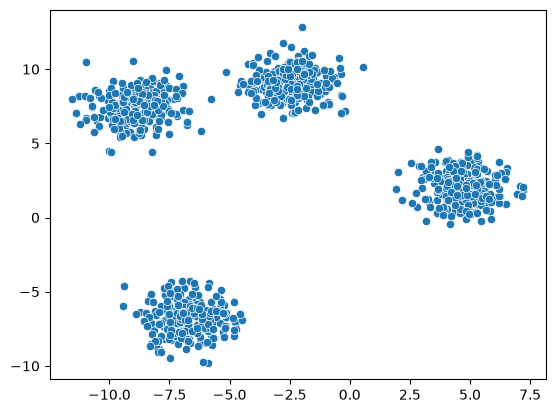

In [3]:
sns.scatterplot(x= X[:,0], y= X[:, 1])

In [4]:
from sklearn.cluster import KMeans

In [5]:
kmeans = KMeans(n_clusters = 4, random_state=42)

In [6]:
labels = kmeans.fit_predict(X)

In [7]:
labels

array([3, 1, 1, 2, 2, 1, 2, 1, 1, 2, 2, 3, 0, 1, 1, 1, 0, 0, 0, 2, 2, 3,
       3, 3, 2, 2, 0, 0, 1, 2, 1, 1, 1, 0, 0, 3, 1, 2, 3, 3, 2, 1, 2, 3,
       2, 3, 0, 2, 3, 2, 1, 0, 2, 3, 0, 3, 0, 0, 0, 1, 1, 0, 1, 3, 2, 0,
       1, 1, 2, 0, 3, 0, 2, 1, 2, 3, 2, 0, 2, 0, 1, 0, 0, 0, 2, 3, 1, 1,
       0, 0, 0, 0, 2, 2, 3, 2, 3, 0, 2, 1, 2, 3, 3, 0, 3, 2, 2, 0, 1, 0,
       3, 1, 2, 2, 2, 2, 1, 3, 1, 2, 0, 1, 3, 2, 3, 1, 2, 3, 1, 2, 0, 1,
       2, 3, 2, 3, 0, 1, 2, 2, 0, 0, 3, 3, 3, 2, 2, 0, 0, 0, 0, 3, 1, 1,
       0, 2, 0, 2, 2, 3, 1, 0, 2, 1, 0, 0, 2, 1, 3, 1, 2, 0, 0, 2, 0, 3,
       1, 3, 1, 3, 2, 2, 0, 1, 0, 1, 2, 3, 0, 1, 2, 0, 2, 2, 0, 3, 1, 1,
       1, 3, 0, 1, 2, 0, 2, 2, 1, 0, 2, 1, 1, 3, 1, 1, 2, 0, 1, 0, 3, 2,
       3, 3, 1, 0, 3, 0, 2, 1, 1, 0, 0, 1, 0, 3, 1, 1, 3, 1, 1, 2, 1, 3,
       1, 2, 3, 0, 2, 0, 2, 2, 2, 2, 3, 2, 2, 1, 0, 1, 1, 2, 2, 2, 3, 2,
       3, 3, 1, 2, 0, 3, 2, 0, 2, 1, 0, 3, 2, 3, 1, 2, 3, 1, 3, 2, 1, 0,
       0, 1, 0, 3, 3, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1,

<Axes: >

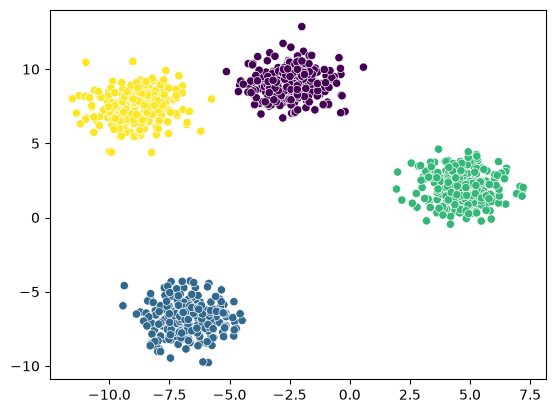

In [8]:
sns.scatterplot(x= X[:,0], y= X[:, 1], c= labels)

## Elbow method (k = 1 … 20)

In [9]:
wcss = []
for k in range (1, 21):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit_predict(X)
    wcss.append(kmeans.inertia_)

In [10]:
wcss

[66908.28490516874,
 31568.656867381324,
 7324.5605647415605,
 1948.7329193856822,
 1791.2305458261158,
 1640.3744893185503,
 1533.8744371582375,
 1336.4651296996926,
 1160.6945975545036,
 1051.5372841691083,
 962.3011372977446,
 911.8415490153604,
 863.6049489653958,
 836.0384838288496,
 756.9863961412539,
 739.7430201183709,
 684.3792775318532,
 659.2679584496216,
 609.255690312923,
 584.6533873532074]

<Axes: >

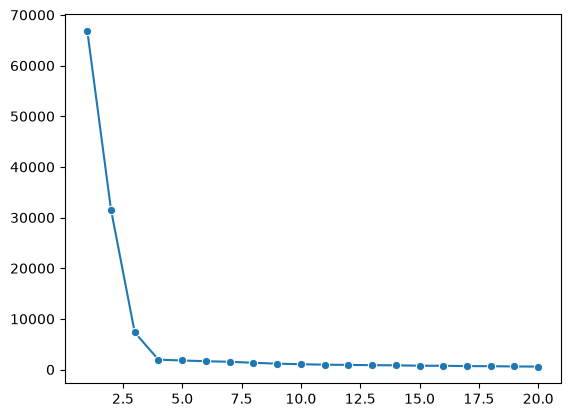

In [11]:
sns.lineplot(x= range(1,21), y= wcss, marker='o')

## Finding the elbow automatically with `kneed`

In [12]:
from kneed import KneeLocator

In [13]:
knee = KneeLocator(range(1,21), wcss,curve="convex", direction="decreasing")

In [14]:
print(knee.knee)

4


## Silhouette score (k = 2 … 20)
Higher is better: points are close to their own cluster and far from others.

In [15]:
from sklearn.metrics import silhouette_score
ss = []
for k in range(2,21):
    kmeans = KMeans(n_clusters=k, random_state=42)
    pred= kmeans.fit_predict(X)
    ss.append(silhouette_score(X, pred))

In [16]:
ss

[0.5895787972208197,
 0.7521964163365819,
 0.7915983870089952,
 0.6799227103294534,
 0.5746150221168222,
 0.5793370458395752,
 0.41637231261626007,
 0.32936331373610966,
 0.3355539566271709,
 0.33462805518152294,
 0.3362266575273926,
 0.3302230144687361,
 0.33026178104632287,
 0.3257799050825757,
 0.32211589254116846,
 0.3224448584008769,
 0.31521006576312866,
 0.3111412509021063,
 0.30760428178616683]

<Axes: >

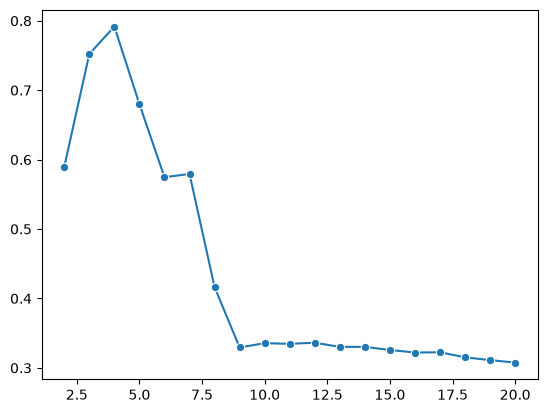

In [17]:
sns.lineplot(y= ss, x= range(2,21), marker= 'o')